# TASK 1: IRIS FLOWER CLASSIFICATION

**Objective:** To build a Machine Learning classification model that predicts the species of an Iris flower based on its physical measurements.

**Technologies Used:** Python, Pandas, NumPy, Matplotlib, Seaborn, Scikit-learn and Jupyter Notebook.

## 1. Dataset Loading

The Iris dataset is a built-in dataset available in the Scikit-learn library. It contains information about three species of Iris flowers: Setosa, Versicolor, and Virginica.

The dataset contains four input features: sepal length, sepal width, petal length, and petal width. These measurements are used to predict the species of the flower.

In [58]:
# Import required libraries

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.datasets import load_iris

# Load the Iris dataset
iris = load_iris()

# Create a DataFrame
df = pd.DataFrame(
    iris.data,
    columns=iris.feature_names
)

# Add species column
df['species'] = iris.target

# Convert numerical labels into species names
df['species'] = df['species'].map({
    0: 'Setosa',
    1: 'Versicolor',
    2: 'Virginica'
})

# Display first five rows
df.head()

,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm),species
0,5.1,3.5,1.4,0.2,Setosa
1,4.9,3.0,1.4,0.2,Setosa
2,4.7,3.2,1.3,0.2,Setosa
3,4.6,3.1,1.5,0.2,Setosa
4,5.0,3.6,1.4,0.2,Setosa


## 2. Exploratory Data Analysis (EDA)

Exploratory Data Analysis (EDA) is performed to understand the dataset, examine its structure, identify missing values, and study the statistical properties of the features.

In [59]:
# Check the shape of the dataset
print("Dataset Shape:", df.shape)

# Check data types
print("\nData Types:")
print(df.dtypes)

# Check missing values
print("\nMissing Values:")
print(df.isnull().sum())

# Display descriptive statistics
print("\nDescriptive Statistics:")
df.describe()

Dataset Shape: (150, 5)

Data Types:
sepal length (cm)    float64
sepal width (cm)     float64
petal length (cm)    float64
petal width (cm)     float64
species                  str
dtype: object

Missing Values:
sepal length (cm)    0
sepal width (cm)     0
petal length (cm)    0
petal width (cm)     0
species              0
dtype: int64

Descriptive Statistics:


,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm)
count,150.000000,150.000000,150.000000,150.000000
mean,5.843333,3.057333,3.758000,1.199333
std,0.828066,0.435866,1.765298,0.762238
min,4.300000,2.000000,1.000000,0.100000
25%,5.100000,2.800000,1.600000,0.300000
50%,5.800000,3.000000,4.350000,1.300000
75%,6.400000,3.300000,5.100000,1.800000
max,7.900000,4.400000,6.900000,2.500000


### EDA Observations

1. The dataset contains 150 rows and 5 columns.
2. It contains four numerical features and one target column (species).
3. There are no missing values in the dataset.
4. The average sepal length is approximately 5.84 cm.
5. The average petal length is approximately 3.76 cm.
6. The dataset is clean and ready for visualisation and model training.

## 3. Data Visualisation

Data visualisation is used to understand the distribution of the Iris flower measurements and identify the differences between the three species.

### 3.1 Pairplot

A pairplot displays the relationship between all four features of the Iris dataset. It helps us understand how the three species are distributed based on their measurements.

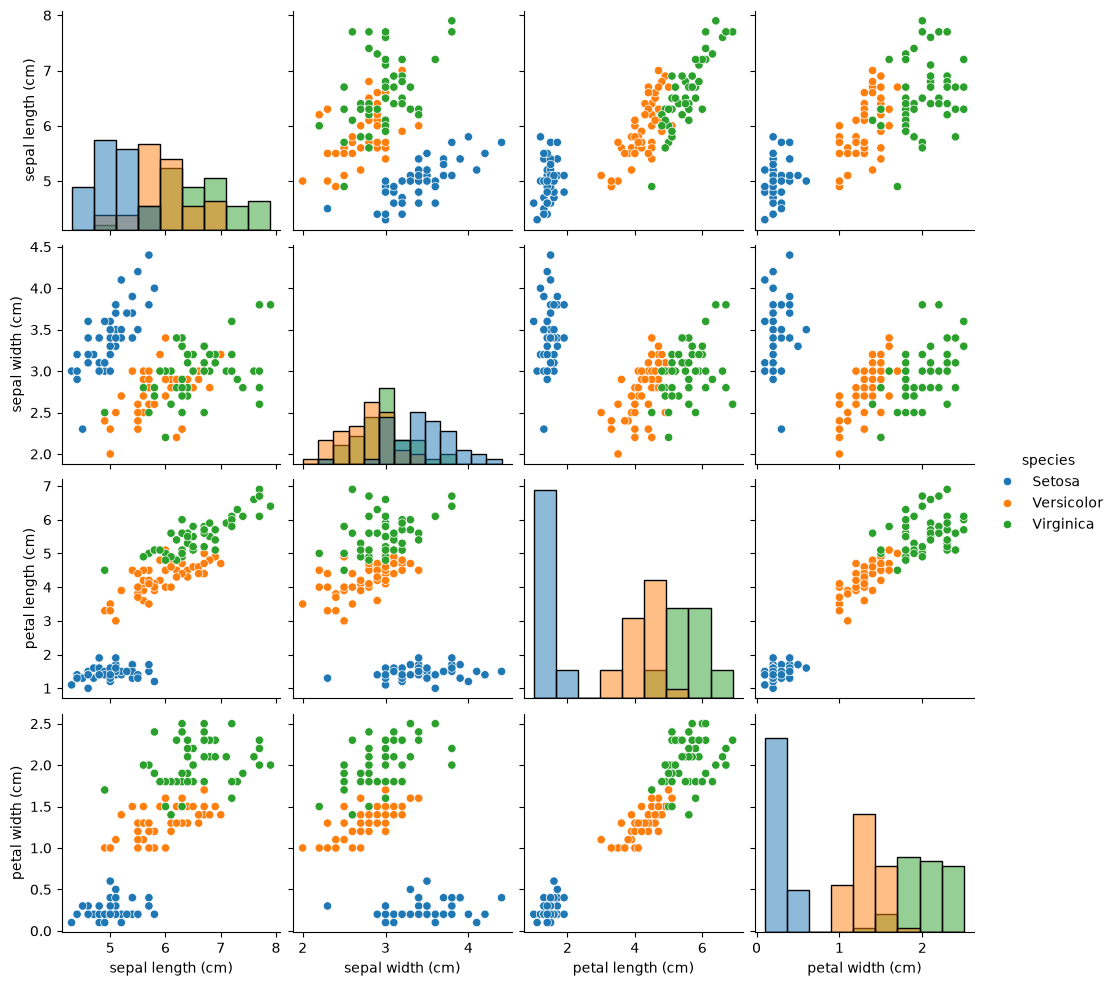

In [60]:
# Create a pairplot to visualize relationships between features

sns.pairplot(
    df,
    hue='species',
    diag_kind='hist'
)

# Display the plot
plt.show()

### 3.2 Box Plots

Box plots are used to understand the distribution of each feature and identify the median, spread, and possible outliers for the three Iris flower species.

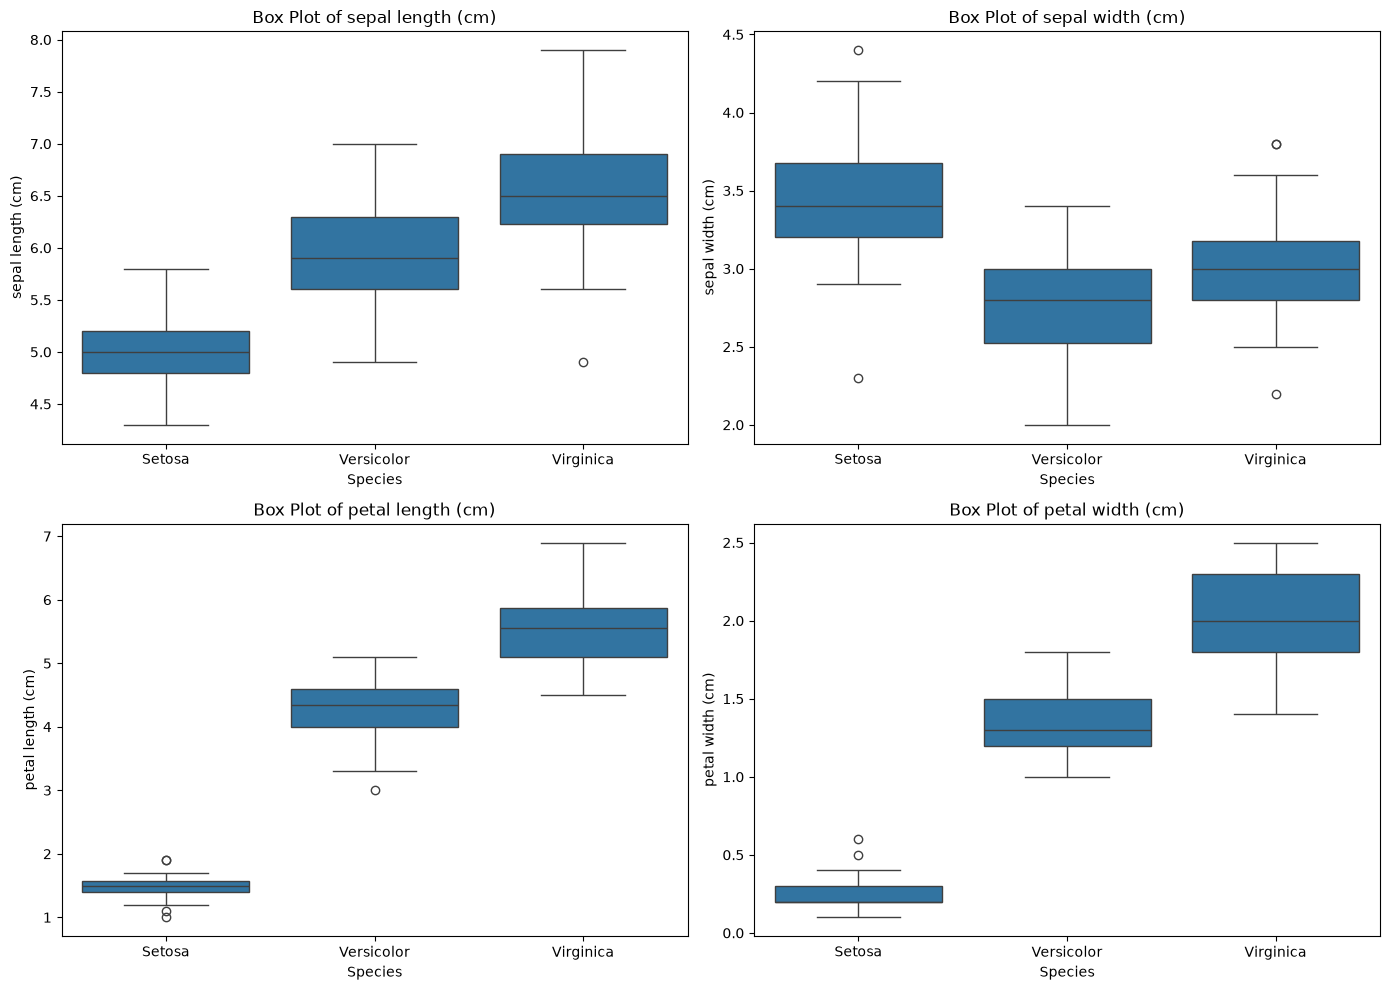

In [61]:
# Create box plots for all four features

features = [
    'sepal length (cm)',
    'sepal width (cm)',
    'petal length (cm)',
    'petal width (cm)'
]

plt.figure(figsize=(14, 10))

for i, feature in enumerate(features, 1):
    plt.subplot(2, 2, i)
    sns.boxplot(data=df, x='species', y=feature)
    plt.title(f'Box Plot of {feature}')
    plt.xlabel('Species')
    plt.ylabel(feature)

plt.tight_layout()
plt.show()

### Box Plot Observations

1. Setosa has smaller petal lengths and petal widths compared to the other two species.
2. Virginica generally has larger petal measurements.
3. Versicolor has intermediate petal measurements.
4. The box plots help compare the spread and distribution of measurements across the three species.

## 4. Feature Selection

Feature selection is the process of identifying the most useful features for predicting the target variable.

In the Iris dataset, the four features are sepal length, sepal width, petal length, and petal width. We analyse these features to identify which measurements help distinguish the three Iris species.

In [62]:
# Calculate the average value of each feature for every species

species_mean = df.groupby('species').mean()

# Display the average measurements
print("Average Feature Values for Each Species:")
species_mean

Average Feature Values for Each Species:


,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm)
species,,,,
Setosa,5.006,3.428,1.462,0.246
Versicolor,5.936,2.770,4.260,1.326
Virginica,6.588,2.974,5.552,2.026


### Feature Selection Observations

1. Petal length is an important feature for distinguishing the three Iris species.
2. Petal width is also highly useful for species classification.
3. Sepal length provides some information for distinguishing the species.
4. Sepal width shows more overlap between the species.
5. Therefore, petal length and petal width are the most discriminative features in this dataset.

All four features will be retained for model training.

## 5. Model Training

Model training is the process of teaching a Machine Learning algorithm to identify patterns in the dataset.

### 5.1 Train-Test Split

The dataset is divided into 80% training data and 20% testing data. The training data is used to train the model, while the testing data is used to evaluate its performance.

In [63]:
# Import train_test_split
from sklearn.model_selection import train_test_split

# Separate input features and target variable
X = df.drop('species', axis=1)
y = df['species']

# Split dataset into 80% training and 20% testing
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

# Display the shapes of training and testing data
print("Training Data Shape:", X_train.shape)
print("Testing Data Shape:", X_test.shape)
print("Training Target Shape:", y_train.shape)
print("Testing Target Shape:", y_test.shape)

Training Data Shape: (120, 4)
Testing Data Shape: (30, 4)
Training Target Shape: (120,)
Testing Target Shape: (30,)


### 5.2 Training Classification Models

Three classification algorithms are used to predict the species of Iris flowers. These models learn from the training data and predict the species using the four flower measurements.

In [64]:
# Import classification algorithms
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier

# Create the models
logistic_model = LogisticRegression(max_iter=200)
knn_model = KNeighborsClassifier(n_neighbors=5)
decision_tree_model = DecisionTreeClassifier(random_state=42)

# Train Logistic Regression
logistic_model.fit(X_train, y_train)

# Train K-Nearest Neighbours
knn_model.fit(X_train, y_train)

# Train Decision Tree
decision_tree_model.fit(X_train, y_train)

print("All three classification models trained successfully!")

All three classification models trained successfully!


## 6. Model Evaluation

Model evaluation is performed to measure how accurately the trained models predict the Iris flower species.

The models are evaluated using accuracy score, confusion matrix, precision, recall, and F1-score.

### 6.1 Accuracy Score

Accuracy score measures the percentage of correctly predicted flower species out of the total predictions.

In [65]:
# Import accuracy score
from sklearn.metrics import accuracy_score

# Make predictions using all three models
y_pred_logistic = logistic_model.predict(X_test)
y_pred_knn = knn_model.predict(X_test)
y_pred_tree = decision_tree_model.predict(X_test)

# Calculate accuracy for each model
accuracy_logistic = accuracy_score(y_test, y_pred_logistic)
accuracy_knn = accuracy_score(y_test, y_pred_knn)
accuracy_tree = accuracy_score(y_test, y_pred_tree)

# Display accuracy scores
print("Logistic Regression Accuracy:", accuracy_logistic)
print("KNN Accuracy:", accuracy_knn)
print("Decision Tree Accuracy:", accuracy_tree)

Logistic Regression Accuracy: 0.9666666666666667
KNN Accuracy: 1.0
Decision Tree Accuracy: 0.9333333333333333


### 6.2 Confusion Matrix

A confusion matrix is used to compare the actual species with the predicted species. It helps identify correct and incorrect predictions made by each classification model.

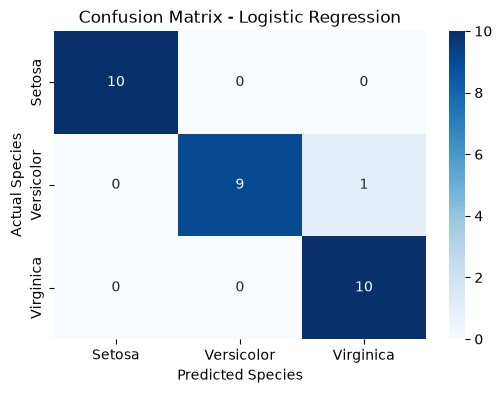

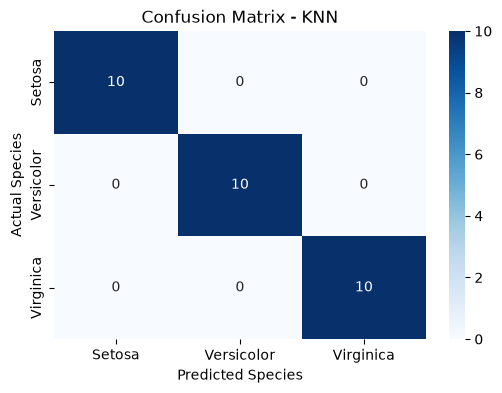

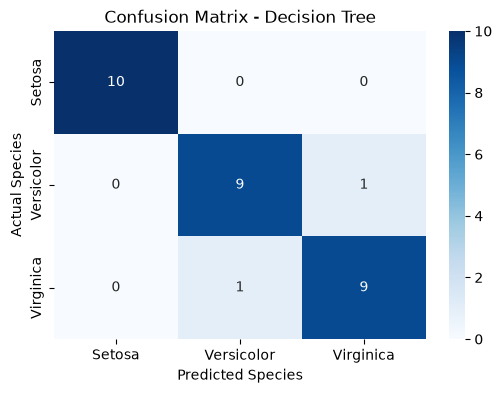

In [66]:
# Import confusion matrix
from sklearn.metrics import confusion_matrix

# Store model predictions
predictions = {
    'Logistic Regression': y_pred_logistic,
    'KNN': y_pred_knn,
    'Decision Tree': y_pred_tree
}

# Plot confusion matrices for all models
for model_name, y_pred in predictions.items():

    cm = confusion_matrix(
        y_test,
        y_pred,
        labels=['Setosa', 'Versicolor', 'Virginica']
    )

    plt.figure(figsize=(6, 4))

    sns.heatmap(
        cm,
        annot=True,
        fmt='d',
        cmap='Blues',
        xticklabels=['Setosa', 'Versicolor', 'Virginica'],
        yticklabels=['Setosa', 'Versicolor', 'Virginica']
    )

    plt.title(f'Confusion Matrix - {model_name}')
    plt.xlabel('Predicted Species')
    plt.ylabel('Actual Species')
    plt.show()

### 6.3 Classification Report

A classification report is used to evaluate the performance of each classification model. It displays three important metrics: Precision, Recall, and F1-score.

- **Precision:** Measures how many predicted results are correct.
- **Recall:** Measures how many actual results are correctly identified.
- **F1-score:** Represents the balance between Precision and Recall.

In [67]:
# Import classification report
from sklearn.metrics import classification_report

# Display classification reports for all models
for model_name, y_pred in predictions.items():

    print(f"\nClassification Report - {model_name}")
    print(classification_report(y_test, y_pred))


Classification Report - Logistic Regression
              precision    recall  f1-score   support

      Setosa       1.00      1.00      1.00        10
  Versicolor       1.00      0.90      0.95        10
   Virginica       0.91      1.00      0.95        10

    accuracy                           0.97        30
   macro avg       0.97      0.97      0.97        30
weighted avg       0.97      0.97      0.97        30


Classification Report - KNN
              precision    recall  f1-score   support

      Setosa       1.00      1.00      1.00        10
  Versicolor       1.00      1.00      1.00        10
   Virginica       1.00      1.00      1.00        10

    accuracy                           1.00        30
   macro avg       1.00      1.00      1.00        30
weighted avg       1.00      1.00      1.00        30


Classification Report - Decision Tree
              precision    recall  f1-score   support

      Setosa       1.00      1.00      1.00        10
  Versicolor    

## 7. Best Model Selection

After evaluating all three classification models, K-Nearest Neighbors (KNN) achieved the highest accuracy of 100%.

Logistic Regression achieved 96.67% accuracy, while Decision Tree achieved 93.33% accuracy.

Therefore, KNN is selected as the best-performing model for this Iris Flower Classification task because it correctly classified all 30 testing samples and achieved the highest precision, recall, and F1-score.

### 7.1 Model Performance Comparison

The performance of the three classification models is compared below:

| Classification Model | Accuracy |
|---|---:|
| Logistic Regression | 96.67% |
| K-Nearest Neighbors (KNN) | 100% |
| Decision Tree | 93.33% |

KNN achieved the highest accuracy among the three models and is selected as the best model for this classification task.

## 8. Conclusion

In this project, we successfully developed a Machine Learning model to classify Iris flowers into three species: Setosa, Versicolor, and Virginica.

The Iris dataset was loaded using Scikit-learn and analysed using Exploratory Data Analysis (EDA) and data visualisation techniques.

Three classification algorithms were trained and evaluated: Logistic Regression, K-Nearest Neighbors (KNN), and Decision Tree.

Among these models, KNN achieved the highest accuracy of 100% on the test dataset.

This project helped us understand data analysis, visualisation, feature selection, model training, and model evaluation using Python.

**Final Result:** K-Nearest Neighbors (KNN) was the best-performing model for this Iris Flower Classification task.